## 1. Dados

In [5]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import spearmanr

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})

# ---------------- parâmetros ----------------
ANO_INICIO, ANO_FIM = 2000, 2025
ALFA = 0.05
PASTA_CACHE = Path('dados_chuva_rn'); PASTA_CACHE.mkdir(exist_ok=True)
PASTA_FIG   = Path('figuras');        PASTA_FIG.mkdir(exist_ok=True)

URL_ONI = 'https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt'
URL_OPENMETEO = 'https://archive-api.open-meteo.com/v1/archive'

# 8 pontos espalhados pelo estado; o "RN" é a média deles
PONTOS_RN = {
    'Natal': (-5.795, -35.209),        'Macau': (-5.115, -36.634),
    'João Câmara': (-5.538, -35.819),  'Santa Cruz': (-6.229, -36.022),
    'Currais Novos': (-6.260, -36.517),'Caicó': (-6.458, -37.098),
    'Pau dos Ferros': (-6.109, -38.204),'Mossoró': (-5.188, -37.344),
}
MESES = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

# ---------------- El Niño: ANOM médio de jan–mar (DJF, JFM, FMA) ----------------
oni = pd.read_csv(URL_ONI, sep=r'\s+', header=0)
oni_ano = (oni[oni['SEAS'].isin(['DJF', 'JFM', 'FMA'])]
           .groupby('YR')['ANOM'].mean().rename('oni'))

# ---------------- chuva: Open-Meteo diária -> mensal -> média dos pontos ----------------
def baixar_chuva(nome, lat, lon):
    arq = PASTA_CACHE / f'{nome}_{ANO_INICIO}_{ANO_FIM}.csv'
    if arq.exists():
        return pd.read_csv(arq, index_col=0, parse_dates=True).iloc[:, 0].rename(nome)
    params = dict(latitude=lat, longitude=lon, start_date=f'{ANO_INICIO}-01-01',
                  end_date=f'{ANO_FIM}-12-31', daily='precipitation_sum', timezone='America/Fortaleza')
    for tentativa in range(5):
        r = requests.get(URL_OPENMETEO, params=params, timeout=120)
        if r.status_code == 200:
            break
        time.sleep(30 * (tentativa + 1))
    else:
        raise RuntimeError(f'Falha ao baixar {nome}: {r.status_code} {r.text[:200]}')
    d = r.json()['daily']
    s = pd.Series(d['precipitation_sum'], index=pd.to_datetime(d['time']), name=nome)
    s.to_frame('precipitation_sum').to_csv(arq)
    return s

diario = pd.concat([baixar_chuva(n, *xy) for n, xy in PONTOS_RN.items()], axis=1)
rn_mensal = diario.resample('MS').sum().mean(axis=1)

# tabela ano × mês (só anos completos)
tab = (pd.DataFrame({'ano': rn_mensal.index.year, 'mes': rn_mensal.index.month, 'mm': rn_mensal.values})
       .pivot(index='ano', columns='mes', values='mm').dropna())

# um valor por ano: intensidade do El Niño + chuva em cada recorte
dados = pd.DataFrame({
    'Ano todo (jan–dez)':       tab.sum(axis=1),
    'Quadra chuvosa (fev–mai)': tab[[2, 3, 4, 5]].sum(axis=1),
}).join(tab.rename(columns=dict(zip(range(1, 13), MESES))), how='inner').join(oni_ano, how='inner')

print(f'{len(dados)} anos ({dados.index.min()}–{dados.index.max()}) | '
      f"chuva anual média {dados['Ano todo (jan–dez)'].mean():.0f} mm | "
      f"quadra = {(dados['Quadra chuvosa (fev–mai)'] / dados['Ano todo (jan–dez)']).mean():.0%} do total")
dados[['oni', 'Ano todo (jan–dez)', 'Quadra chuvosa (fev–mai)']].round(2).head()

26 anos (2000–2025) | chuva anual média 652 mm | quadra = 62% do total


,oni,Ano todo (jan–dez),Quadra chuvosa (fev–mai)
2000,-1.24,733.30,393.84
2001,-0.58,386.35,245.94
2002,0.01,541.74,288.75
2003,0.62,572.70,384.69
2004,0.27,761.42,356.50


## 2. Cálculo das correlações

In [6]:
def holm(ps):
    ps = np.asarray(ps, float); ordem = np.argsort(ps); m = len(ps)
    aj = np.empty(m); corrente = 0.0
    for pos, i in enumerate(ordem):
        corrente = max(corrente, (m - pos) * ps[i]); aj[i] = min(1.0, corrente)
    return aj

def forca(rho):
    a = abs(rho)
    return 'desprezível' if a < .1 else 'fraca' if a < .3 else 'moderada' if a < .5 else 'forte'

def correlacao(coluna):
    d = dados[['oni', coluna]].dropna()
    rho, p = spearmanr(d['oni'], d[coluna])
    slope = stats.theilslopes(d[coluna], d['oni'])[0]          # mm por °C de ANOM
    return dict(janela=coluna, rho=rho, p=p, n=len(d), mm_por_graus=slope,
                pct_da_media=100 * slope / d[coluna].mean(), forca=forca(rho))

# ---- testes principais (2): ano todo e quadra
principal = pd.DataFrame([correlacao(c) for c in ['Ano todo (jan–dez)', 'Quadra chuvosa (fev–mai)']])
principal['p_holm'] = holm(principal['p'])

# ---- onde (12 meses): exploratório
mensal = pd.DataFrame([correlacao(m) for m in MESES])
mensal['p_holm'] = holm(mensal['p'])

# rho mínimo para p < 0,05 com este n (referência visual)
n_ref = int(principal['n'].iloc[0])
t_crit = stats.t.ppf(1 - ALFA / 2, n_ref - 2)
rho_crit = t_crit / np.sqrt(n_ref - 2 + t_crit ** 2)

cols = ['janela', 'rho', 'p', 'p_holm', 'n', 'forca', 'mm_por_graus', 'pct_da_media']
print('TESTES PRINCIPAIS')
print(principal[cols].round(3).to_string(index=False))
print('\nMÊS A MÊS (ANOM jan–mar × chuva do mês)')
print(mensal[cols].round(3).to_string(index=False))
print(f'\nCom n = {n_ref} anos, só |rho| ≥ {rho_crit:.2f} chega a p < {ALFA}.')

TESTES PRINCIPAIS
                  janela    rho     p  p_holm  n forca  mm_por_graus  pct_da_media
      Ano todo (jan–dez) -0.158 0.440   0.685 26 fraca       -53.233        -8.160
Quadra chuvosa (fev–mai) -0.194 0.343   0.685 26 fraca       -57.268       -13.838

MÊS A MÊS (ANOM jan–mar × chuva do mês)
janela    rho     p  p_holm  n       forca  mm_por_graus  pct_da_media
   Jan  0.209 0.306   1.000 26       fraca        10.150        14.379
   Fev  0.125 0.544   1.000 26       fraca         7.836         8.805
   Mar -0.019 0.925   1.000 26 desprezível         1.796         1.337
   Abr -0.380 0.056   0.612 26    moderada       -27.268       -23.322
   Mai -0.275 0.175   1.000 26       fraca       -11.354       -15.435
   Jun -0.043 0.833   1.000 26 desprezível        -0.622        -1.056
   Jul -0.306 0.128   1.000 26    moderada        -7.145       -15.619
   Ago -0.599 0.001   0.015 26       forte        -5.016       -37.164
   Set -0.262 0.196   1.000 26       fraca        -1.

## 3. Resposta

In [7]:
def sentido(rho):
    return 'negativa (mais El Niño → menos chuva)' if rho < 0 else 'positiva (mais El Niño → mais chuva)'

confirmadas = principal[principal['p_holm'] < ALFA]
indicios    = principal[(principal['p'] < ALFA) & (principal['p_holm'] >= ALFA)]
resposta = 'SIM' if len(confirmadas) else 'NÃO'

linha = '=' * 78
print(linha)
print(f'EXISTE CORRELAÇÃO ENTRE A INTENSIDADE DO EL NIÑO E A DAS CHUVAS NO RN?   →   {resposta}')
print(linha)

print('\nTESTES PRINCIPAIS')
for _, r in principal.iterrows():
    achou = '✅' if r['p_holm'] < ALFA else '❌'
    print(f"  {achou} {r['janela']:<26} rho = {r['rho']:+.2f} ({r['forca']}, {sentido(r['rho']).split(' (')[0]})   "
          f"p = {r['p']:.3f}   p corrigido = {r['p_holm']:.3f}")
    if r['p_holm'] < ALFA:
        print(f"       cada +1 °C de ANOM ↔ {r['mm_por_graus']:+.0f} mm de chuva ({r['pct_da_media']:+.0f} % da média)")

print('\nONDE (mês a mês, ANOM jan–mar × chuva do mês)')
sig = mensal[mensal['p'] < ALFA]
if len(sig) == 0:
    mx = mensal.loc[mensal['rho'].abs().idxmax()]
    print(f"  Nenhum mês com p < {ALFA}. Maior |rho|: {mx['janela']} (rho = {mx['rho']:+.2f}, p = {mx['p']:.3f}).")
else:
    for _, r in sig.iterrows():
        extra = ' ← resiste à correção para 12 meses' if r['p_holm'] < ALFA else ''
        print(f"  • {r['janela']}: rho = {r['rho']:+.2f} ({r['forca']}, {sentido(r['rho']).split(' (')[0]}), p = {r['p']:.3f}{extra}")
    print(f"  ({len(sig)} de 12 meses com p < {ALFA}; por acaso, esperaríamos ~0,6.)")

print('\nCOMO LER')
if resposta == 'SIM':
    r0 = confirmadas.sort_values('p').iloc[0]
    print(f"  Há correlação {sentido(r0['rho'])} em «{r0['janela']}» (rho = {r0['rho']:+.2f}, n = {r0['n']} anos).")
    print(f"  O El Niño explica cerca de {100 * r0['rho'] ** 2:.0f} % da variação da chuva desse recorte; o resto vem de outros fatores (ex.: Atlântico tropical).")
else:
    print('  Não há evidência estatística de correlação neste período e com estes dados.')
    if len(indicios):
        print(f"  Atenção: «{', '.join(indicios['janela'])}» teve p < {ALFA} sem correção, mas não resiste à correção para 2 testes: é indício, não confirmação.")
    print(f'  "NÃO" não prova ausência de efeito: com {n_ref} anos, só correlações de |rho| ≥ {rho_crit:.2f} seriam detectadas.')
print(linha)

EXISTE CORRELAÇÃO ENTRE A INTENSIDADE DO EL NIÑO E A DAS CHUVAS NO RN?   →   NÃO

TESTES PRINCIPAIS
  ❌ Ano todo (jan–dez)         rho = -0.16 (fraca, negativa)   p = 0.440   p corrigido = 0.685
  ❌ Quadra chuvosa (fev–mai)   rho = -0.19 (fraca, negativa)   p = 0.343   p corrigido = 0.685

ONDE (mês a mês, ANOM jan–mar × chuva do mês)
  • Ago: rho = -0.60 (forte, negativa), p = 0.001 ← resiste à correção para 12 meses
  (1 de 12 meses com p < 0.05; por acaso, esperaríamos ~0,6.)

COMO LER
  Não há evidência estatística de correlação neste período e com estes dados.
  "NÃO" não prova ausência de efeito: com 26 anos, só correlações de |rho| ≥ 0.39 seriam detectadas.


## 4. Gráficos

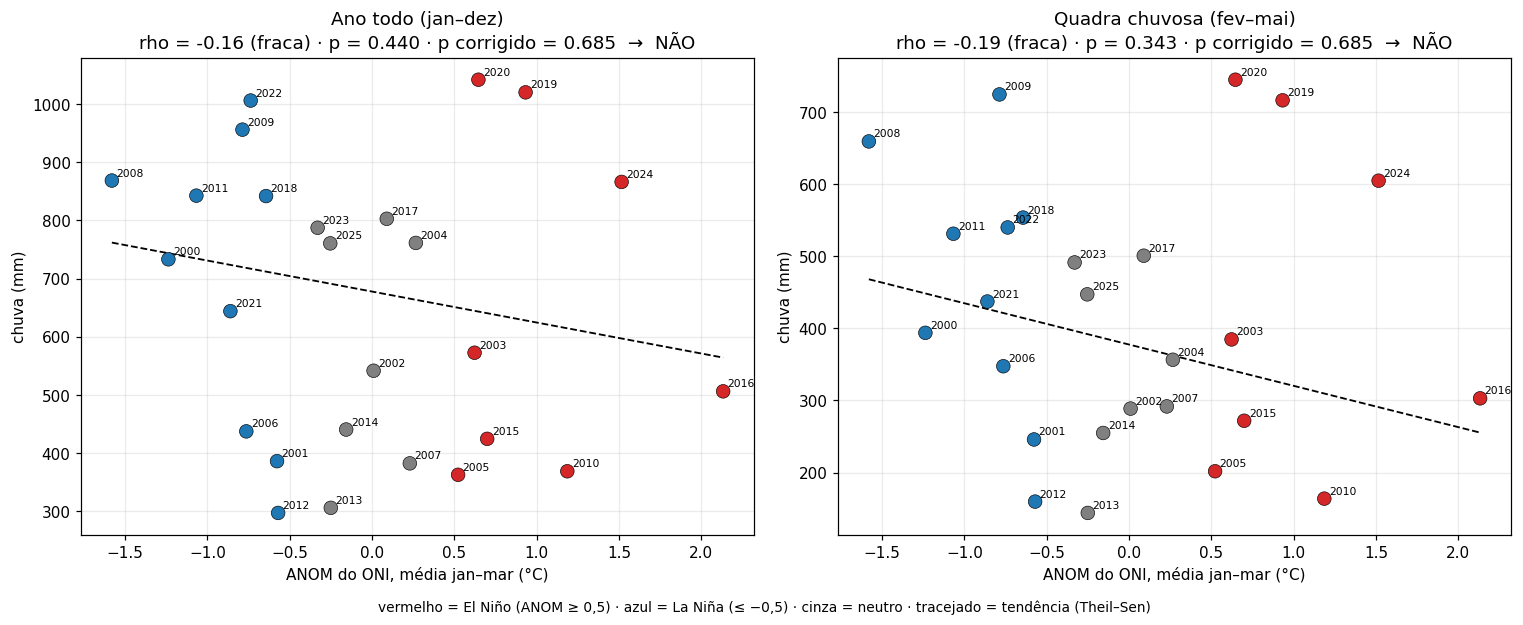

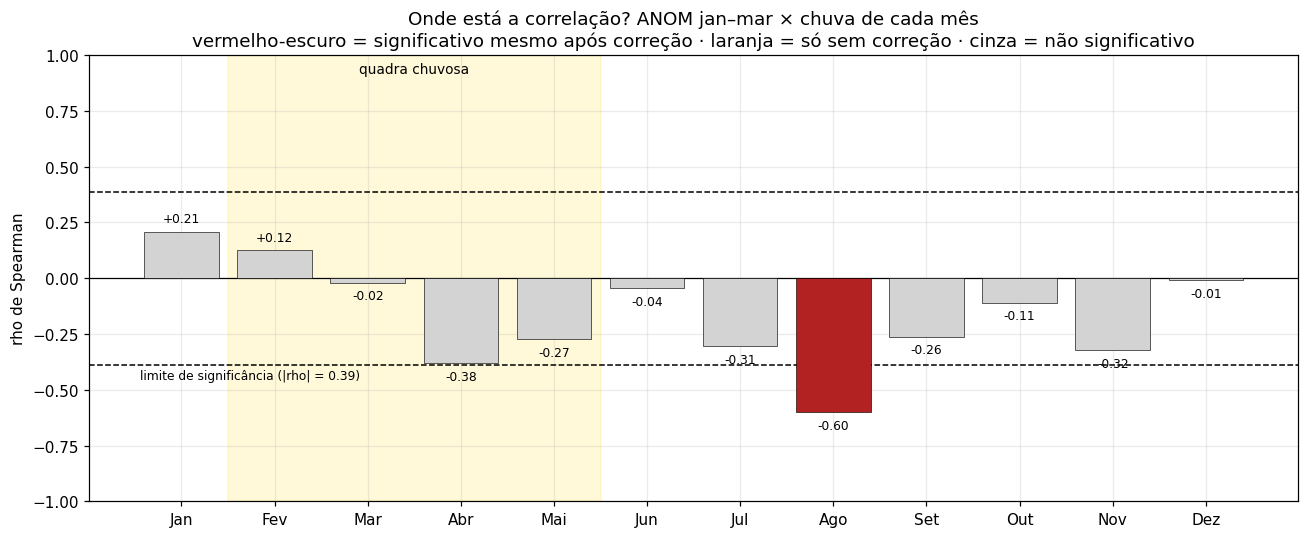

Salvos: figuras/fig1_testes_principais.png, figuras/fig2_onde_por_mes.png, resultados_correlacao.csv


In [8]:
def cor_ponto(v):
    return 'tab:red' if v >= 0.5 else 'tab:blue' if v <= -0.5 else 'gray'

# ---- Figura 1: os dois testes principais
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True)
for a, (_, r) in zip(ax, principal.iterrows()):
    y = dados[r['janela']]
    a.scatter(dados['oni'], y, s=80, c=[cor_ponto(v) for v in dados['oni']], edgecolor='k', lw=.4, zorder=3)
    for ano, row in dados.iterrows():
        a.annotate(str(ano), (row['oni'], row[r['janela']]), fontsize=7, xytext=(3, 3), textcoords='offset points')
    sl, ic, _, _ = stats.theilslopes(y, dados['oni'])
    xs = np.linspace(dados['oni'].min(), dados['oni'].max(), 50)
    a.plot(xs, ic + sl * xs, 'k--', lw=1.2)
    veredito = 'SIM' if r['p_holm'] < ALFA else 'NÃO'
    a.set_title(f"{r['janela']}\nrho = {r['rho']:+.2f} ({r['forca']}) · p = {r['p']:.3f} · p corrigido = {r['p_holm']:.3f}  →  {veredito}")
    a.set_xlabel('ANOM do ONI, média jan–mar (°C)'); a.set_ylabel('chuva (mm)')
fig.text(0.5, -0.02, 'vermelho = El Niño (ANOM ≥ 0,5) · azul = La Niña (≤ −0,5) · cinza = neutro · tracejado = tendência (Theil–Sen)', ha='center', fontsize=9)
plt.tight_layout(); fig.savefig(PASTA_FIG / 'fig1_testes_principais.png', dpi=150, bbox_inches='tight'); plt.show()

# ---- Figura 2: onde? (rho por mês)
fig, ax = plt.subplots(figsize=(12, 5))
cores = ['firebrick' if h < ALFA else 'orange' if p < ALFA else 'lightgray'
         for p, h in zip(mensal['p'], mensal['p_holm'])]
ax.bar(MESES, mensal['rho'], color=cores, edgecolor='k', lw=.4, zorder=3)
ax.axvspan(0.5, 4.5, color='gold', alpha=.15, zorder=0)
ax.text(2.5, 0.97, 'quadra chuvosa', ha='center', va='top', fontsize=9)
for y_ in (rho_crit, -rho_crit):
    ax.axhline(y_, color='k', ls='--', lw=1)
ax.text(-0.45, -rho_crit - .02, f'limite de significância (|rho| = {rho_crit:.2f})', ha='left', va='top', fontsize=8)
ax.axhline(0, color='k', lw=.8)
for i, v in enumerate(mensal['rho']):
    ax.text(i, v + (0.03 if v >= 0 else -0.03), f'{v:+.2f}', ha='center', va='bottom' if v >= 0 else 'top', fontsize=8)
ax.set_ylim(-1, 1); ax.set_ylabel('rho de Spearman')
ax.set_title('Onde está a correlação? ANOM jan–mar × chuva de cada mês\n'
             'vermelho-escuro = significativo mesmo após correção · laranja = só sem correção · cinza = não significativo')
plt.tight_layout(); fig.savefig(PASTA_FIG / 'fig2_onde_por_mes.png', dpi=150, bbox_inches='tight'); plt.show()

pd.concat([principal, mensal]).round(4).to_csv('resultados_correlacao.csv', index=False)
print('Salvos: figuras/fig1_testes_principais.png, figuras/fig2_onde_por_mes.png, resultados_correlacao.csv')